<a href="https://colab.research.google.com/github/BioML-UGent/Advanced-AI-for-Bioinformatics/blob/main/05_calibration/05_calibration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PC lab 5: Calibration of machine learning models

A classifier gives us a predicted class, but often we also need its **probability**. A model can classify most samples correctly while giving probabilities that are too high or too low. **Calibration** asks whether these probabilities agree with the observed outcomes. Among samples given a probability of 0.8 for class 1, about 80% should actually belong to class 1.

In **part 1**, we compare two binary classifiers and calibrate both with Platt scaling and isotonic regression. In **part 2**, we reuse the CNN of PC lab 3 for Fashion-MNIST, measure two kinds of multiclass calibration error, and apply temperature scaling.

**Learning goals**
- Measure binary calibration with a reliability diagram and expected calibration error (ECE)
- Fit Platt scaling and isotonic regression on held-out calibration data
- Distinguish confidence ECE from classwise ECE
- Calibrate the probabilities of a trained CNN with one temperature parameter


## 0 Setup

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

torch.manual_seed(42)
np.random.seed(42)


# Part 1: Binary classification

## 1 Two classifiers on the same data

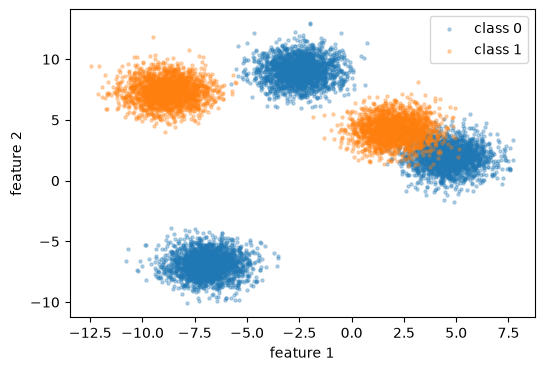

In [2]:
X_bin, cluster = make_blobs(n_samples=10000, centers=5, n_features=2, random_state=42)
y_bin = (cluster > 2).astype(int)

fig, ax = plt.subplots(figsize=(6, 4))
for c in [0, 1]:
    ax.scatter(X_bin[y_bin == c, 0], X_bin[y_bin == c, 1],
               s=5, alpha=0.3, label=f"class {c}")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.legend()
plt.show()


<div class="alert alert-success">

<b>EXERCISE 1: train two classifiers</b>

a) Split the data into a test set (50%) and a remaining set (50%). Split the remaining set equally into training and calibration data. Use `stratify` on the labels in both splits, so that the class proportions are similar.

b) Create a random forest with `n_estimators=100` and `max_depth=4`, and a KNN classifier with `n_neighbors=10`. Fit both on the training set only.

c) <b>THINK:</b> Why do we need a calibration set as well as a training and a test set?

</div>

a)


In [ ]:
######## YOUR CODE HERE #########
X_rest_bin, X_test_bin, y_rest_bin, y_test_bin = train_test_split(
    ..., ..., test_size=..., random_state=42, stratify=...)
X_train_bin, X_cal_bin, y_train_bin, y_cal_bin = train_test_split(
    ..., ..., test_size=..., random_state=42, stratify=...)
#################################

print("training:", len(y_train_bin), "calibration:", len(y_cal_bin), "test:", len(y_test_bin))

b)


In [ ]:
######## YOUR CODE HERE #########
models_bin = {
    "random forest": ...,
    "KNN": ...,
}
for clf in models_bin.values():
    clf.fit(..., ...)
#################################


c)


**Your answer:**


## 2 Reliability diagrams and binary ECE

Let `p` be the predicted probability of **class 1**, and let `y` be 0 or 1. A **reliability diagram** groups predictions into bins and plots the mean predicted probability against the fraction of class-1 samples in each bin. Perfect calibration follows the diagonal; points above it have a higher observed fraction of positives than predicted.

The **expected calibration error (ECE)** summarizes the absolute gaps, weighted by the number of samples in each bin:

$$\mathrm{ECE} = \sum_{b=1}^{B}\frac{n_b}{N}
\left|\overline{p}_b-\overline{y}_b\right|.$$

We use 10 equal-width bins between 0 and 1. Empty bins contribute nothing. ECE is an estimate: a bin containing only a few samples has an uncertain observed fraction. Its value also depends on the number of bins, so use the same bins when comparing models.


<div class="alert alert-success">

<b>EXERCISE 2: compare the uncalibrated models</b>

a) Complete `ece` below. For every nonempty bin, collect the mean probability, the fraction of positives and the number of samples. The bin assignment is supplied: `np.digitize(p, edges[1:-1])` gives indices 0–9 and correctly includes both 0 and 1.

b) Predict class-1 probabilities on the test set for both classifiers and print their ECEs.

c) <b>THINK:</b> Can a model have high classification accuracy and still have poorly calibrated probabilities? What else affects the ECE estimate?

</div>

a)


In [ ]:
def bin_stats(p, y, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    bin_index = np.digitize(p, edges[1:-1])
    p_means, y_means, counts = [], [], []
    for b in range(n_bins):
        mask = bin_index == b
        if mask.any():
            p_means.append(p[mask].mean())
            y_means.append(y[mask].mean())
            counts.append(mask.sum())
    return np.array(p_means), np.array(y_means), np.array(counts)

######## YOUR CODE HERE #########
def ece(p, y, n_bins=10):
    p_means, y_means, counts = bin_stats(p, y, n_bins)
    return ...
#################################


The small plotting helper below uses the same bin statistics. We will reuse it for all reliability diagrams.


In [ ]:
def plot_reliability(p, y, ax, label):
    p_means, y_means, counts = bin_stats(p, y)
    ax.plot(p_means, y_means, "o-", label=label)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("mean predicted probability")
    ax.set_ylabel("fraction of positives")


b)


In [ ]:
######## YOUR CODE HERE #########
p_test_bin = {}
print(f"{'model':16s} {'ECE':>10s}")
for name, clf in models_bin.items():
    p_test_bin[name] = ...  # keep the pred for class 1
    error = ...
    print(f"{name:16s} {error:10.4f}")
#################################


c)


**Your answer:**


## 3 Platt scaling and isotonic regression

**Platt scaling** fits a sigmoid to the classifier's output score `s`:

$$q(s)=\sigma(as+b).$$

The two parameters are learned from the calibration set. This is a simple, smooth correction; for our classifiers, scikit-learn obtains the scores from their predicted probabilities.

**Isotonic regression** learns a **non-decreasing**, piecewise constant map from scores to probabilities. It is more flexible than a sigmoid, but this also makes it easier to overfit a small calibration set.

Both methods change the probabilities after training. We use [`CalibratedClassifierCV`](https://scikit-learn.org/1.8/modules/generated/sklearn.calibration.CalibratedClassifierCV.html) with `FrozenEstimator(clf)`, which keeps the fitted classifier fixed. Fitting on `X_cal_bin` then learns only the calibration map. All comparisons below use the same test samples.


<div class="alert alert-success">

<b>EXERCISE 3: calibrate both classifiers</b>

a) For <b>each</b> trained classifier, fit a `CalibratedClassifierCV` with `method="sigmoid"` (Platt scaling) and one with `method="isotonic"`. Wrap the classifier in `FrozenEstimator` and fit on the calibration set only.

b) Run the supplied cell to compare the six sets of probabilities: two classifiers, each uncalibrated, Platt-scaled and isotonic-calibrated. It prints an ECE table and plots the reliability diagrams.

c) <b>THINK:</b> Which method gives the lowest test ECE for each classifier? Does calibration always improve ECE, and why might the two classifiers benefit differently?

</div>


a)


In [ ]:
######## YOUR CODE HERE #########
calibrated_bin = {}
for name, clf in models_bin.items():
    calibrated_bin[name] = {"uncalibrated": clf}
    for method in ["sigmoid", "isotonic"]:
        cal_clf = ...
        cal_clf.fit(..., ...)
        calibrated_bin[name][method] = cal_clf
#################################


b)


In [ ]:
methods = ["uncalibrated", "sigmoid", "isotonic"]
labels = ["uncalibrated", "Platt", "isotonic"]
binary_ece = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
print(f"{'model':16s} {'uncalibrated':>13s} {'Platt':>10s} {'isotonic':>10s}")
for ax, (name, variants) in zip(axes, calibrated_bin.items()):
    binary_ece[name] = {}
    for method, label in zip(methods, labels):
        p = variants[method].predict_proba(X_test_bin)[:, 1]
        binary_ece[name][method] = ece(p, y_test_bin)
        plot_reliability(p, y_test_bin, ax, label)
    errors = [binary_ece[name][method] for method in methods]
    print(f"{name:16s} {errors[0]:13.4f} {errors[1]:10.4f} {errors[2]:10.4f}")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()


c)


**Your answer:**


---

# Part 2: Multiclass classification with a CNN

## 4 Fashion-MNIST and the CNN of PC lab 3

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) contains 28 × 28 grayscale images of clothes in 10 classes. The input and output shapes are the same as for the MNIST CNN of PC lab 3.

The supplied cell uses a fixed random split of the official training data: **10,000 training images** and **5,000 calibration images**. We leave the remaining training images unused to keep the run short. The official test set contains 10,000 separate images. We divide pixels by 255 and keep their 2D structure: `(N, 1, 28, 28)`.

The calibration images will be used only to fit the temperature. The number of training epochs is fixed in advance; we do not use these images for early stopping or model selection.


In [ ]:
# HTTPS mirror provided by the Fashion-MNIST authors
datasets.FashionMNIST.mirrors = [
    "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
]
train_data = datasets.FashionMNIST(root="data", train=True, download=True)
test_data = datasets.FashionMNIST(root="data", train=False, download=True)

perm = torch.randperm(len(train_data.data), generator=torch.Generator().manual_seed(42))
train_idx, cal_idx = perm[:10000], perm[10000:15000]
X_train_fashion = train_data.data[train_idx].float().unsqueeze(1) / 255
y_train_fashion = train_data.targets[train_idx]
X_cal_fashion = train_data.data[cal_idx].float().unsqueeze(1) / 255
y_cal_fashion = train_data.targets[cal_idx]
X_test_fashion = test_data.data.float().unsqueeze(1) / 255
y_test_fashion = test_data.targets

train_loader = DataLoader(TensorDataset(X_train_fashion, y_train_fashion), batch_size=64, shuffle=True)
cal_loader = DataLoader(TensorDataset(X_cal_fashion, y_cal_fashion), batch_size=1000, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_fashion, y_test_fashion), batch_size=1000, shuffle=False)
print(X_train_fashion.shape, X_cal_fashion.shape, X_test_fashion.shape)


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for c, ax in enumerate(axes.flat):
    i = (y_train_fashion == c).nonzero()[0].item()
    ax.imshow(X_train_fashion[i, 0], cmap="gray")
    ax.set_title(train_data.classes[c])
    ax.axis("off")
plt.tight_layout()
plt.show()


The class and training helper below are the familiar code from PC labs 2 and 3. Two convolution → ReLU → pooling blocks reduce the image from 28 × 28 to 7 × 7, with 32 channels. The final linear layer therefore takes `32*7*7` inputs and produces 10 **logits**.

We supply this code so that you can focus on calibration.


In [ ]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    batch_losses = []
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    return batch_losses


<div class="alert alert-success">

<b>EXERCISE 4: train the CNN</b>

a) Create a `SmallCNN`, the cross-entropy loss and an Adam optimizer with learning rate 0.001. Train for <b>20 epochs</b> with `train_one_epoch` and print the mean batch loss after each epoch. Keep the seed supplied below.

b) <b>THINK:</b> Why does `CrossEntropyLoss` take logits instead of probabilities? Which activation will we apply when we need probabilities?

</div>


a)


In [ ]:
######## YOUR CODE HERE #########
torch.manual_seed(0)
cnn = ...
loss_fn = ...
optimizer = ...
for epoch in range(1, 3):
    batch_losses = train_one_epoch(cnn, train_loader, loss_fn, optimizer)
    print(f"epoch {epoch}: training loss {np.mean(batch_losses):.3f}")
#################################


b)


**Your answer:**


## 5 Confidence ECE and classwise ECE

With 10 classes, there are several ways to assess calibration.

**Confidence ECE** only considers the probability of the **predicted class**. For each sample, take its maximum probability and whether its prediction is correct (1) or wrong (0). Use our binary `ece` function on these values: it compares the mean confidence with the accuracy in every bin.

**Classwise ECE** considers **every class**, even when that class was not predicted. For class `c`, compare `probs[:, c]` with the one-vs-rest label `(y == c)`, then average the 10 binary ECEs:

$$\mathrm{ECE}_{\mathrm{classwise}}
=\frac{1}{10}\sum_{c=0}^{9}\mathrm{ECE}\big(p_c,\mathbb{1}[y=c]\big).$$

These measure different aspects of calibration. A small confidence ECE does not guarantee good probabilities for every class. Keep the same 10-bin scheme for all calculations.

The helper below collects logits without tracking gradients.

In [ ]:
def collect_logits(model, loader):
    model.eval()
    logits_list, labels_list = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            logits_list.append(model(X_batch))
            labels_list.append(y_batch)
    return torch.cat(logits_list), torch.cat(labels_list)


<div class="alert alert-success">

<b>EXERCISE 5: measure multiclass calibration</b>

a) Complete `confidence_ece` and `classwise_ece` using the earlier `ece` function. Collect the calibration and test logits with `collect_logits`, and convert the test logits to probabilities with `torch.softmax(..., dim=1).numpy()`. Print both test ECEs.

b) <b>THINK:</b> Why do we compare confidence with correctness, but each class probability with a one-vs-rest label? Does a small confidence ECE guarantee a small classwise ECE?

</div>


a)


In [ ]:
######## YOUR CODE HERE #########
def confidence_ece(probs, y):
    confidence = ...
    correct = ...
    return ece(confidence, correct)


def classwise_ece(probs, y):
    errors = []
    for c in range(probs.shape[1]):
        errors.append(ece(..., ...))
    return np.mean(errors)


logits_cal, labels_cal = collect_logits(cnn, cal_loader)
logits_test, labels_test = collect_logits(cnn, test_loader)
probs_test = ...
y_test_mc = labels_test.numpy()
print(f"confidence ECE: {confidence_ece(probs_test, y_test_mc):.4f}")
print(f"classwise ECE:  {classwise_ece(probs_test, y_test_mc):.4f}")
#################################


b)


**Your answer:**


## 6 Temperature scaling

**Temperature scaling** divides all logits by one positive number `T` before applying softmax:

$$p_{n,c}^{(T)}
=\frac{\exp(z_{n,c}/T)}{\sum_k\exp(z_{n,k}/T)}.$$

We fit `T` by minimizing cross-entropy on the **calibration logits**, while keeping the CNN fixed. Writing `T = exp(log_T)` ensures that the temperature is positive; the usual gradient-descent steps can then optimize `log_T`.

`T > 1` makes the distribution softer (less confident), `T < 1` makes it sharper, and `T = 1` leaves it unchanged. Dividing all logits by the same positive number preserves their order, so the predicted class and accuracy stay the same. The probabilities, and therefore both ECEs, can change.


<div class="alert alert-success">

<b>EXERCISE 6: fit a temperature and compare ECE</b>

a) Complete the two missing expressions in the supplied optimization loop: the positive temperature and the cross-entropy of `logits_cal / T`. Only `log_T` is optimized; the CNN and its detached logits stay fixed.

b) Apply the fitted temperature to the test logits. Run the supplied comparison cell to print both ECEs before and after scaling, check that predicted classes agree, and plot a confidence reliability diagram.

c) <b>THINK:</b> Did both ECEs improve in your run? Interpret the fitted temperature and explain why ECE can change while accuracy stays the same.

</div>


a)


In [ ]:
cnn.requires_grad_(False)
logits_cal = logits_cal.detach()
log_T = torch.tensor(0.0, requires_grad=True)
temp_optimizer = torch.optim.Adam([log_T], lr=0.05)
temp_loss_fn = nn.CrossEntropyLoss()

for step in range(200):
    temp_optimizer.zero_grad()
    ######## YOUR CODE HERE #########
    T = ...
    loss = ...
    #################################
    loss.backward()
    temp_optimizer.step()


b)


In [ ]:
######## YOUR CODE HERE #########
T = log_T.exp().detach().item()
probs_scaled = ...
#################################

print(f"fitted temperature: {T:.3f}")
print("same predicted classes:", np.array_equal(probs_test.argmax(axis=1), probs_scaled.argmax(axis=1)))
print(f"{'model':18s} {'confidence ECE':>15s} {'classwise ECE':>15s}")
multiclass_ece = {}
fig, ax = plt.subplots(figsize=(6, 4))
for name, probs in [("uncalibrated", probs_test), ("temperature", probs_scaled)]:
    multiclass_ece[name] = (confidence_ece(probs, y_test_mc), classwise_ece(probs, y_test_mc))
    conf_error, class_error = multiclass_ece[name]
    print(f"{name:18s} {conf_error:15.4f} {class_error:15.4f}")
    plot_reliability(probs.max(axis=1), probs.argmax(axis=1) == y_test_mc, ax, name)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("mean confidence")
ax.set_ylabel("accuracy")
ax.set_title("Fashion-MNIST: confidence calibration")
ax.legend()
plt.tight_layout()
plt.show()


c)


**Your answer:**
